In [1]:
from langchain_core.messages import AIMessage, HumanMessage

messages = [AIMessage(content="Please tell me how can I help", name="LLMModel")]
messages.append(HumanMessage(content="I want to learn coding", name="Arpit"))
messages.append(AIMessage(content="Which programming language you want to learn", name="LLM Model"))
messages.append(HumanMessage(content="I want to learn python programming language", name="Arpit"))

for message in messages:
    message.pretty_print()

================================== Ai Message ==================================
Name: LLMModel

Please tell me how can I help
================================ Human Message =================================
Name: Arpit

I want to learn coding
================================== Ai Message ==================================
Name: LLM Model

Which programming language you want to learn
================================ Human Message =================================
Name: Arpit

I want to learn python programming language


In [ ]:
import sys
from pathlib import Path
from dotenv import find_dotenv, load_dotenv

# Add project root to sys.path so llm_config can be imported from any subdirectory
for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (p / "llm_config.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

from llm_config import get_llm, list_free_models

def add(a: int, b: int) -> int:
    """Add a and b
    Args:
        a (int): first int
        b (int): second int
    Returns:
        int
    """
    return a + b

# Load environment variables (ensure GROQ_API_KEY is set in your .env)
load_dotenv(find_dotenv())

# Initialize Groq model with automatic multi-model fallback
llm = get_llm(temperature=0.7)
llm_with_tools = get_llm(temperature=0.7, tools=[add])
tool_call = llm_with_tools.invoke([HumanMessage(content="What is 2 plus 2", name="Arpit")])


In [3]:
from langgraph.graph.message import add_messages
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage

class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

initial_messages = [AIMessage(content="Please tell me how can I help", name="LLMModel")]
initial_messages.append(HumanMessage(content="I want to learn coding", name="Arpit"))
ai_message = AIMessage(content="Which programming language you want to learn", name="LLMModel")
add_messages(initial_messages, ai_message)


[AIMessage(content='Please tell me how can I help', additional_kwargs={}, response_metadata={}, name='LLMModel', id='92b49a5c-2565-4b05-8e18-57962b1d852d', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='I want to learn coding', additional_kwargs={}, response_metadata={}, name='Arpit', id='7c0ea3fe-0f8a-4f3d-867a-36b7efeae10a'),
 AIMessage(content='Which programming language you want to learn', additional_kwargs={}, response_metadata={}, name='LLMModel', id='85b14784-a10d-463f-8ea5-a0d7791eed8d', tool_calls=[], invalid_tool_calls=[])]

In [4]:
from langgraph.constants import END
from langgraph.constants import START
from langgraph.graph.state import StateGraph
import langgraph.graph.state

def llm_tool(state: State):
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("llm_tool", llm_tool)
builder.add_edge(START, "llm_tool")
builder.add_edge("llm_tool", END)
graph = builder.compile()

# Graph Visualization for graph
from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_ascii())
messages = graph.invoke({"messages": "What is 2 plus 2"})

for message in messages["messages"]:
    message.pretty_print()

================================ Human Message =================================

What is 2 plus 2
================================== Ai Message ==================================
Tool Calls:
  add (3jwnm108t)
 Call ID: 3jwnm108t
  Args:
    a: 2
    b: 2


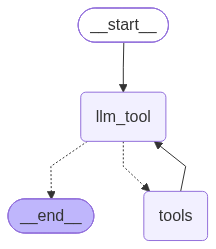

In [5]:
from langgraph.prebuilt import ToolNode, tools_condition

tools = [add]
builder = StateGraph(State)
builder.add_node("llm_tool", llm_tool)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "llm_tool")

builder.add_conditional_edges(
                                "llm_tool",
                                # tool call in last message -> "tools" ; otherwise -> END
                                tools_condition
                                )
                                
# ✅ Loop back to LLM so it can read the ToolMessage and generate the final answer:
builder.add_edge("tools", "llm_tool")
graph_builder = builder.compile()

# Graph Visualization for graph_builder
from IPython.display import Image, display
try:
    display(Image(graph_builder.get_graph().draw_mermaid_png()))
except Exception:
    print(graph_builder.get_graph().draw_ascii())


In [8]:
messages = graph_builder.invoke({"messages": "What is 2 plus 2"})
messages["messages"]
for message in messages["messages"]:
    message.pretty_print()

================================ Human Message =================================

What is 2 plus 2
================================== Ai Message ==================================
Tool Calls:
  add (3tze05n9a)
 Call ID: 3tze05n9a
  Args:
    a: 2
    b: 2
================================= Tool Message =================================
Name: add

4
================================== Ai Message ==================================

2 plus 2 equals 4.


In [9]:
messages = graph_builder.invoke({"messages": "What Machine Learning"})
for message in messages["messages"]:
    message.pretty_print()

================================ Human Message =================================

What Machine Learning
================================== Ai Message ==================================

Machine Learning (ML) is a branch of artificial intelligence (AI) that focuses on building systems that can learn from data. Instead of being explicitly programmed with rules for every possible scenario, ML algorithms use statistical methods to identify patterns in data and make predictions or decisions.

Here is a simple breakdown:

1.  **Data-Driven**: It relies on large datasets to train models.
2.  **Learning**: The system improves its performance over time as it is exposed to more data.
3.  **Prediction/Decision**: The ultimate goal is to predict outcomes (e.g., "Will this customer buy this product?") or make decisions (e.g., "Is this email spam?").

**Common Types of Machine Learning:**
*   **Supervised Learning**: Learning from labeled data (input + correct output). Examples: Spam detection, hous